# Set 1: EDA + Simple Linear Regression

**Q1 → Exp 1A / 1B** · **Q2 → Exp 3** (simple linear regression)

Datasets: Q1 `Diabetes.csv`. Q2 asks for `Rampur.csv`, which we don't have, so this uses **`Kasol.csv`**: same kind of river data, with the same `Wind` and `Discharge` columns. In the exam, change only the file name.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 Display the columns with null values

In [3]:
nulls = df.isnull().sum()
print(nulls)
print("\nColumns with null values:", list(nulls[nulls > 0].index))

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Columns with null values: []


Diabetes has no empty cells, but a **0** in Glucose, BloodPressure, SkinThickness, Insulin or BMI is impossible, so those zeros are really hidden missing values (good viva point).

### Q1.3 5-number summary of a numerical column, correlated with a box plot

min      0.00
25%     99.00
50%    117.00
75%    140.25
max    199.00
Name: Glucose, dtype: float64


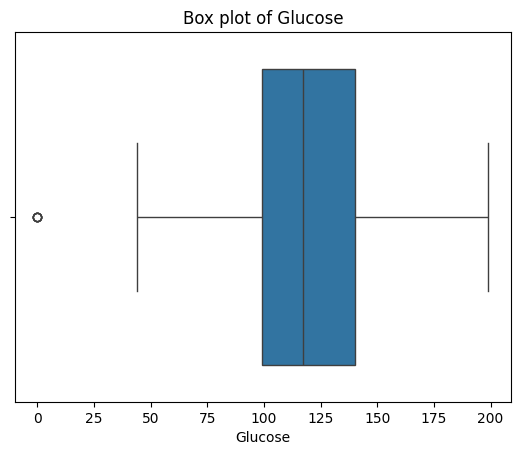

In [4]:
col = "Glucose"
print(df[col].describe()[["min", "25%", "50%", "75%", "max"]])     # the 5-number summary

sns.boxplot(x=df[col])
plt.title("Box plot of " + col)
plt.show()

**Correlate with the box plot:** left edge of the box = 25%, middle line = 50% (median), right edge = 75%, whiskers reach towards min and max, and dots beyond the whiskers are outliers.

### Q1.4 Bivariate analysis: continuous vs categorical (categorical plot)

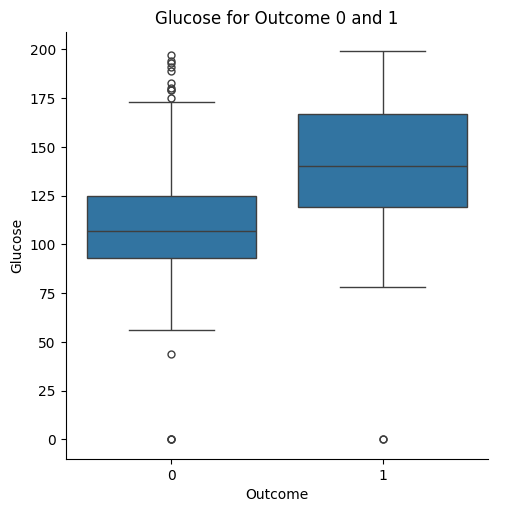

In [5]:
sns.catplot(x="Outcome", y="Glucose", data=df, kind="box")
plt.title("Glucose for Outcome 0 and 1")
plt.show()

People with diabetes (Outcome = 1) have clearly higher Glucose.

### Q1.5 Drop rows with an outlier (Z-score > 3 in any column) and display the size

In [6]:
num = df.select_dtypes("number")
z = ((num - num.mean()) / num.std()).abs()      # z-score of every value
df_clean = df[(z <= 3).all(axis=1)]              # keep rows where EVERY column has |z| <= 3
print("Before:", df.shape)
print("After :", df_clean.shape)

Before: (768, 9)
After : (688, 9)


---
## Question 2

### Q2.1 Read and divide into training (75%) and testing (25%)

In [7]:
kasol = pd.read_csv("data/Kasol.csv").dropna()      # drop the empty lines
X = kasol[["Wind"]]                                   # double brackets: X must be a table
y = kasol["Discharge"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5468, 1)  Test: (1823, 1)


### Q2.2 Impact of Wind on Discharge: intercept and coefficient

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)
print("Intercept  :", round(model.intercept_, 4))
print("Coefficient:", model.coef_.round(4))

Intercept  : 1045.3113
Coefficient: [-161.3566]


### Q2.3 Predict discharge for the test set

In [9]:
y_pred = model.predict(X_test)
pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head()

,Actual,Predicted
0,128.40,456.359826
1,180.00,46.514149
2,84.20,253.050553
3,85.80,320.820311
4,778.94,336.955967


### Q2.4 Display the regression line

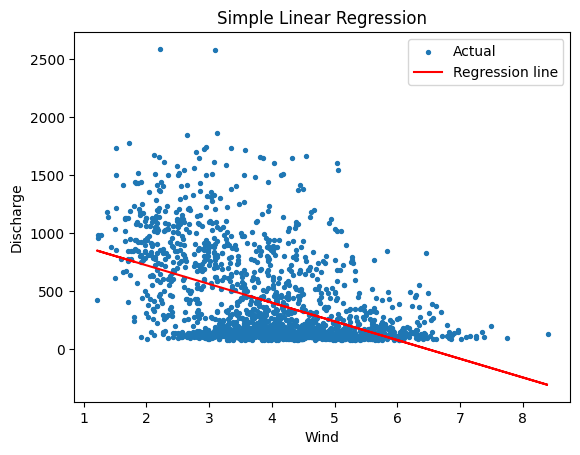

In [10]:
plt.scatter(X_test, y_test, s=8, label="Actual")
plt.plot(X_test, y_pred, color="red", label="Regression line")
plt.xlabel("Wind")
plt.ylabel("Discharge")
plt.legend()
plt.title("Simple Linear Regression")
plt.show()

### Q2.5 MSE and RMSE

In [11]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
print("MSE :", round(mse, 2))
print("RMSE:", round(np.sqrt(mse), 2))

MSE : 117031.24
RMSE: 342.1


Wind alone explains discharge poorly (large RMSE), which is why Set 2 uses **many** columns.